### Import Data & Library

### Install Library

In [1]:
%pip install pandas numpy scikit-learn imbalanced-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


### Import Library

In [2]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (make_scorer, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, roc_auc_score, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

Matplotlib is building the font cache; this may take a moment.


### Import Data

In [3]:
df = pd.read_csv('HR Employee.csv')
df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


# EDA

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

### Analisis Deskriptif

In [5]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,...,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,36.923810,802.485714,9.192517,2.912925,1.0,1024.865306,2.721769,65.891156,2.729932,2.063946,...,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,9.135373,403.509100,8.106864,1.024165,0.0,602.024335,1.093082,20.329428,0.711561,1.106940,...,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,491.250000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,802.000000,7.000000,3.000000,1.0,1020.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1555.750000,4.000000,83.750000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


### Missing Value

In [6]:
print("Total missing :", df.isna().sum().sum())
print("Duplikat baris:", df.duplicated().sum())

Total missing : 0
Duplikat baris: 0


### Distribusi Attrition

In [7]:
# Distribusi target
tgt = df["Attrition"].map({"Yes": 1, "No": 0}) if df["Attrition"].isin(["Yes", "No"]).all() else df["Attrition"]
counts = tgt.value_counts().sort_index()
print(counts, "\nProporsi:\n", tgt.value_counts(normalize=True).round(4))

Attrition
0    1233
1     237
Name: count, dtype: int64 
Proporsi:
 Attrition
0    0.8388
1    0.1612
Name: proportion, dtype: float64


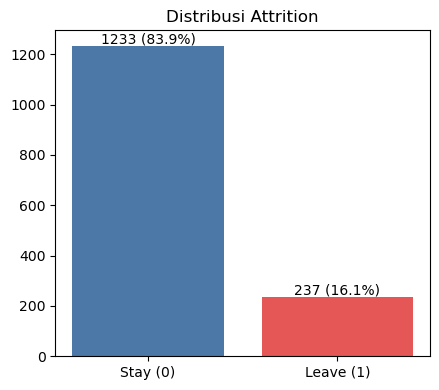

Imbalance ratio (mayoritas:minoritas) = 5.20 : 1


In [8]:
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.bar(["Stay (0)", "Leave (1)"], counts.values, color=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, f"{v} ({v/len(tgt):.1%})", ha="center")
ax.set_title("Distribusi Attrition"); plt.tight_layout(); plt.show()
print(f"Imbalance ratio (mayoritas:minoritas) = {counts[0]/counts[1]:.2f} : 1")

### Feature Engineering

In [9]:
# Buang kolom ID/konstan jika masih ada
drop_cols = [c for c in ["EmployeeCount", "StandardHours", "Over18", "EmployeeNumber"] if c in df.columns]
df = df.drop(columns=drop_cols)

# Target 0/1 (hanya dikonversi jika masih teks)
if df["Attrition"].isin(["Yes", "No"]).all():
    df["Attrition"] = (df["Attrition"] == "Yes").astype(int)
assert set(df["Attrition"].unique()) <= {0, 1}

# Fitur turunan
df["IncomePerYearExp"] = df["MonthlyIncome"] / (df["TotalWorkingYears"] + 1)
df["PromotionGap"]     = df["YearsSinceLastPromotion"] / (df["YearsAtCompany"] + 1)
df["SatisfactionMean"] = df[["JobSatisfaction", "EnvironmentSatisfaction",
                             "RelationshipSatisfaction", "WorkLifeBalance"]].mean(axis=1)

# Pengelompokan tipe fitur (dipakai seluruh anggota)
CONT = ["Age", "DailyRate", "DistanceFromHome", "HourlyRate", "MonthlyIncome",
        "MonthlyRate", "NumCompaniesWorked", "PercentSalaryHike", "TotalWorkingYears",
        "TrainingTimesLastYear", "YearsAtCompany", "YearsInCurrentRole",
        "YearsSinceLastPromotion", "YearsWithCurrManager",
        "IncomePerYearExp", "PromotionGap", "SatisfactionMean"]
ORD  = ["Education", "EnvironmentSatisfaction", "JobInvolvement", "JobLevel",
        "JobSatisfaction", "PerformanceRating", "RelationshipSatisfaction",
        "StockOptionLevel", "WorkLifeBalance"]
CAT  = ["BusinessTravel", "Department", "EducationField", "Gender",
        "JobRole", "MaritalStatus", "OverTime"]

missing = [c for c in CONT + ORD + CAT if c not in df.columns]
extra   = [c for c in df.columns if c not in CONT + ORD + CAT + ["Attrition"]]
assert not missing, f"Kolom hilang: {missing}"
print("Kolom tidak terpakai:", extra)    # idealnya []

Kolom tidak terpakai: []


### Korelasi Data

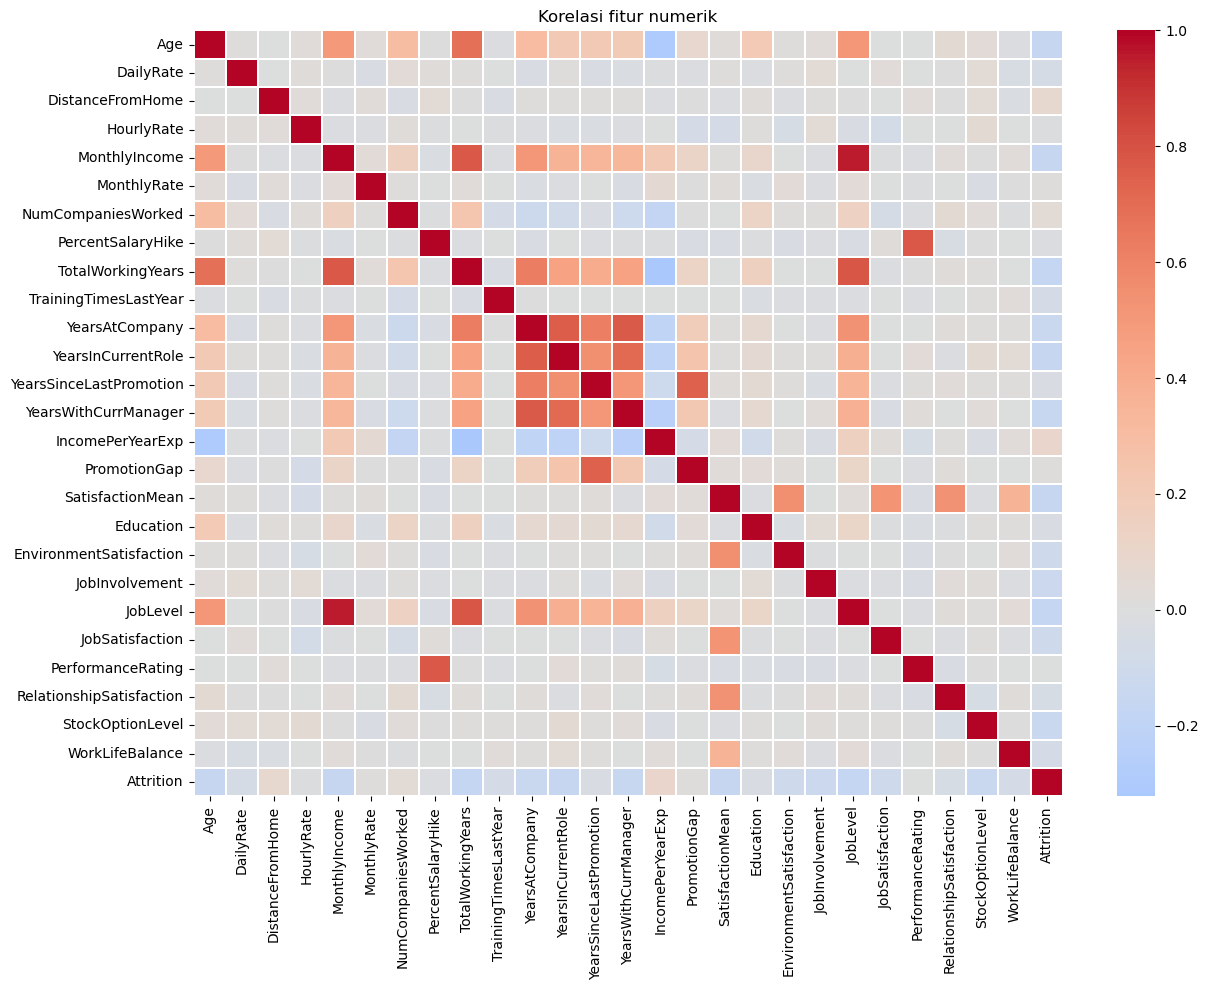

10 fitur paling berkorelasi dengan Attrition:
 TotalWorkingYears      -0.171
JobLevel               -0.169
YearsInCurrentRole     -0.161
MonthlyIncome          -0.160
Age                    -0.159
SatisfactionMean       -0.159
YearsWithCurrManager   -0.156
StockOptionLevel       -0.137
YearsAtCompany         -0.134
JobInvolvement         -0.130
Name: Attrition, dtype: float64

Pasangan korelasi > 0.7:
 MonthlyIncome            JobLevel                0.950
TotalWorkingYears        JobLevel                0.782
PercentSalaryHike        PerformanceRating       0.774
MonthlyIncome            TotalWorkingYears       0.773
YearsAtCompany           YearsWithCurrManager    0.769
                         YearsInCurrentRole      0.759
YearsSinceLastPromotion  PromotionGap            0.745
YearsInCurrentRole       YearsWithCurrManager    0.714
dtype: float64


In [10]:
num_cols = CONT + ORD
corr = df[num_cols + ["Attrition"]].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=False, linewidths=.3)
plt.title("Korelasi fitur numerik"); plt.tight_layout(); plt.show()

top = corr["Attrition"].drop("Attrition").sort_values(key=abs, ascending=False).head(10)
print("10 fitur paling berkorelasi dengan Attrition:\n", top.round(3))

# Pasangan fitur sangat berkorelasi (indikasi multikolinearitas)
c = corr.drop("Attrition").drop(columns="Attrition").abs()
pairs = (c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
           .sort_values(ascending=False))
print("\nPasangan korelasi > 0.7:\n", pairs[pairs > 0.7].round(3))

                         n_outlier  persen
TrainingTimesLastYear          238   16.19
MonthlyIncome                  114    7.76
YearsSinceLastPromotion        107    7.28
YearsAtCompany                 104    7.07
TotalWorkingYears               63    4.29
NumCompaniesWorked              52    3.54
IncomePerYearExp                43    2.93
SatisfactionMean                36    2.45
YearsInCurrentRole              21    1.43
YearsWithCurrManager            14    0.95
DailyRate                        0    0.00
PercentSalaryHike                0    0.00
MonthlyRate                      0    0.00
HourlyRate                       0    0.00
DistanceFromHome                 0    0.00
PromotionGap                     0    0.00
Age                              0    0.00


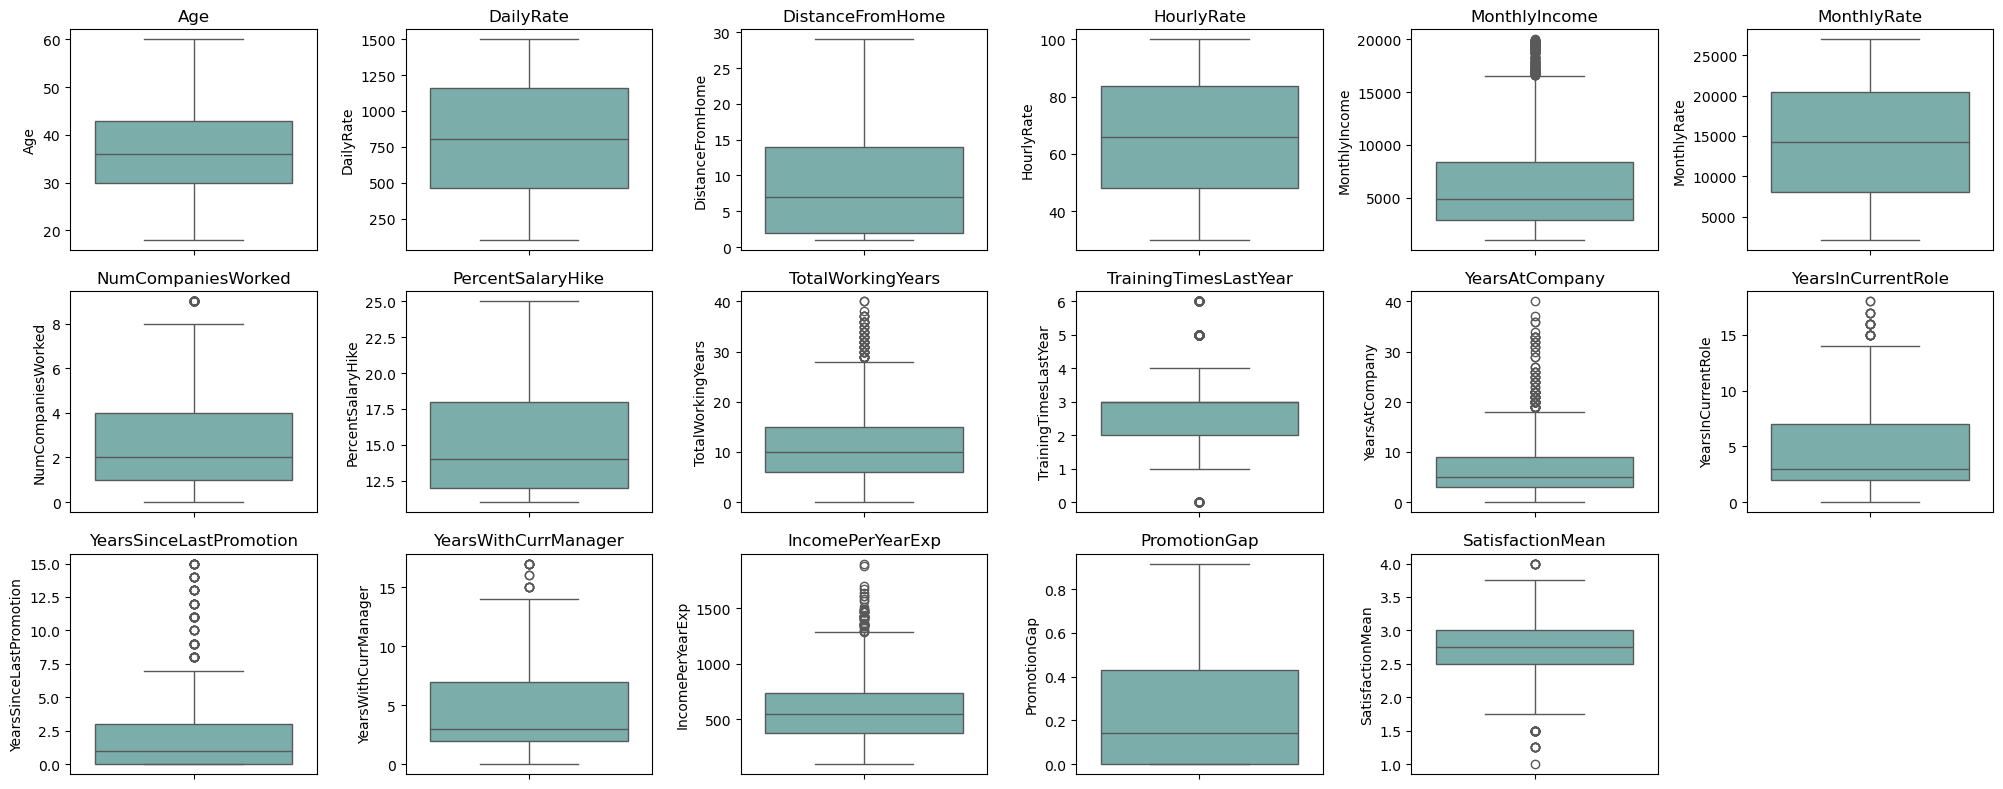

In [11]:
# Outlier (metode IQR): hanya dilaporkan, tidak dibuang
def iqr_outliers(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)).sum()

out_tbl = pd.DataFrame({"n_outlier": {c: iqr_outliers(df[c]) for c in CONT}})
out_tbl["persen"] = (out_tbl["n_outlier"] / len(df) * 100).round(2)
print(out_tbl.sort_values("n_outlier", ascending=False))

fig, axes = plt.subplots(3, 6, figsize=(20, 8)); axes = axes.ravel()
for ax, col in zip(axes, CONT):
    sns.boxplot(y=df[col], ax=ax, color="#72B7B2"); ax.set_title(col)
for ax in axes[len(CONT):]: ax.axis("off")
plt.tight_layout(); plt.show()

# Pembuatan Model

### Split Data

In [12]:
SEED = 42

X = df.drop(columns="Attrition")
y = df["Attrition"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test = X_train.reset_index(drop=True), X_test.reset_index(drop=True)
y_train, y_test = y_train.reset_index(drop=True), y_test.reset_index(drop=True)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Attrition train:", y_train.mean().round(4), "| test:", y_test.mean().round(4))

Train: (1176, 33) | Test: (294, 33)
Attrition train: 0.1616 | test: 0.1599


### Pembuatan Fungsi Model Baseline dan Pipeline

In [13]:
def make_preprocessor(extra_num=()):
    """Scaling fitur numerik + one-hot kategorikal. Di-fit hanya pada data train tiap fold."""
    return ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD + list(extra_num)),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])

def make_model(name, class_weight=None):
    if name == "LogReg":
        return LogisticRegression(max_iter=2000, class_weight=class_weight, random_state=SEED)
    if name == "RandForest":      # parameter default (baseline)
        return RandomForestClassifier(class_weight=class_weight, random_state=SEED, n_jobs=-1)
    raise ValueError(name)

def build_pipeline(model_name, imb=None):
    """
    imb: None | 'cw' (class weight) | 'smote'
    Resampling berada DI DALAM pipeline: hanya dijalankan saat fit (data train fold),
    tidak pernah menyentuh data validasi.
    """
    steps = [("pre", make_preprocessor())]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    cw = "balanced" if imb == "cw" else None
    steps.append(("clf", make_model(model_name, class_weight=cw)))
    return ImbPipeline(steps)

### Pembuatan Fungsi Cross Validation dan Metrik Evaluasi

In [14]:
SCORING = {
    "Precision": make_scorer(precision_score, zero_division=0),
    "Recall":    make_scorer(recall_score),
    "F1":        make_scorer(f1_score),
    "BalAcc":    make_scorer(balanced_accuracy_score),
    "ROC_AUC":   "roc_auc",
    "PR_AUC":    "average_precision",
}

def get_cv(n_splits=5):
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)

def run_cv(pipeline, X, y, n_splits=5):
    """Stratified k-fold. Mengembalikan rata-rata dan simpangan baku tiap metrik."""
    res = cross_validate(pipeline, X, y, cv=get_cv(n_splits), scoring=SCORING,
                         n_jobs=1, error_score="raise")
    out = {}
    for m in SCORING:
        out[m] = res[f"test_{m}"].mean()
        out[f"{m}_std"] = res[f"test_{m}"].std()
    return out

def oof_proba(pipeline, X, y, n_splits=5):
    """Probabilitas out-of-fold (untuk threshold tuning)."""
    return cross_val_predict(pipeline, X, y, cv=get_cv(n_splits), method="predict_proba")[:, 1]

def compute_metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {"Precision": precision_score(y_true, pred, zero_division=0),
            "Recall":    recall_score(y_true, pred),
            "F1":        f1_score(y_true, pred),
            "BalAcc":    balanced_accuracy_score(y_true, pred),
            "ROC_AUC":   roc_auc_score(y_true, proba),
            "PR_AUC":    average_precision_score(y_true, proba)}

### Menampilkan Hasil Smote Pada Data Train

,Sebelum,Sesudah SMOTE,Sintetis ditambahkan
Stay (0),986,986,0
Leave (1),190,986,796


Proporsi Leave: 16.2% -> 50.0%


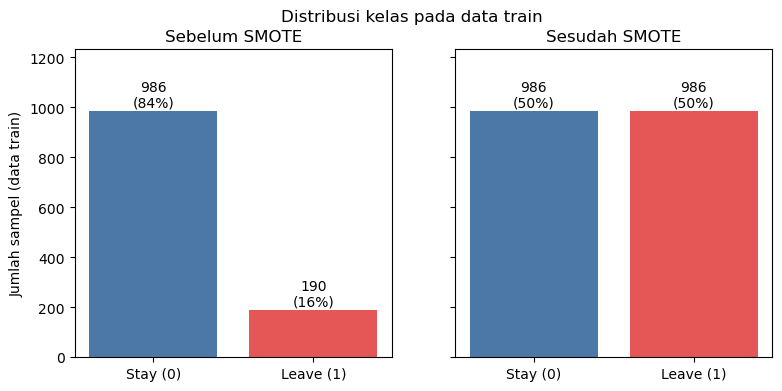

In [15]:
from imblearn.over_sampling import SMOTE

pre = make_preprocessor()
Xp = pre.fit_transform(X_train)                       # fit di data train saja
Xs, ys = SMOTE(random_state=SEED).fit_resample(Xp, y_train)

# Tabel ringkas
before = y_train.value_counts().sort_index()
after = pd.Series(ys).value_counts().sort_index()
tbl = pd.DataFrame({"Sebelum": before, "Sesudah SMOTE": after}, index=[0, 1])
tbl.index = ["Stay (0)", "Leave (1)"]
tbl["Sintetis ditambahkan"] = tbl["Sesudah SMOTE"] - tbl["Sebelum"]
display(tbl)
print(f"Proporsi Leave: {before[1]/before.sum():.1%} -> {after[1]/after.sum():.1%}")

# Grafik
fig, axes = plt.subplots(1, 2, figsize=(9, 4), sharey=True)
for ax, (name, c) in zip(axes, [("Sebelum SMOTE", before), ("Sesudah SMOTE", after)]):
    ax.bar(["Stay (0)", "Leave (1)"], c.values, color=["#4C78A8", "#E45756"])
    for i, v in enumerate(c.values):
        ax.text(i, v + 15, f"{v}\n({v/c.sum():.0%})", ha="center")
    ax.set_title(name); ax.set_ylim(0, after.max() * 1.25)
axes[0].set_ylabel("Jumlah sampel (data train)")
plt.suptitle("Distribusi kelas pada data train")
plt.show()

### Train Model Baseline

In [16]:
IMB_OPTIONS = {"Tanpa penanganan": None, "Class weight": "cw", "SMOTE": "smote"}
rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        r = run_cv(build_pipeline(model_name, imb), X_train, y_train)
        r.update(Model=model_name, Imbalance=imb_name)
        rows.append(r)
        print(f"{model_name:10s} | {imb_name:17s} | F1={r['F1']:.3f}±{r['F1_std']:.3f} "
              f"Recall={r['Recall']:.3f} PR_AUC={r['PR_AUC']:.3f}")
        
cv_baseline = pd.DataFrame(rows)

# Tabel ringkas mean ± std
show = cv_baseline[["Model", "Imbalance"]].copy()
for m in ["Precision", "Recall", "F1", "ROC_AUC", "PR_AUC"]:
    show[m] = cv_baseline.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(show)

LogReg     | Tanpa penanganan  | F1=0.570±0.080 Recall=0.453 PR_AUC=0.667
LogReg     | Class weight      | F1=0.488±0.025 Recall=0.732 PR_AUC=0.624
LogReg     | SMOTE             | F1=0.495±0.029 Recall=0.700 PR_AUC=0.608
RandForest | Tanpa penanganan  | F1=0.349±0.116 Recall=0.232 PR_AUC=0.571
RandForest | Class weight      | F1=0.290±0.100 Recall=0.179 PR_AUC=0.564
RandForest | SMOTE             | F1=0.417±0.067 Recall=0.300 PR_AUC=0.573


,Model,Imbalance,Precision,Recall,F1,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.779 ± 0.069,0.453 ± 0.082,0.570 ± 0.080,0.841 ± 0.030,0.667 ± 0.059
1,LogReg,Class weight,0.368 ± 0.026,0.732 ± 0.071,0.488 ± 0.025,0.829 ± 0.031,0.624 ± 0.077
2,LogReg,SMOTE,0.384 ± 0.023,0.700 ± 0.079,0.495 ± 0.029,0.826 ± 0.032,0.608 ± 0.068
3,RandForest,Tanpa penanganan,0.846 ± 0.097,0.232 ± 0.096,0.349 ± 0.116,0.816 ± 0.029,0.571 ± 0.046
4,RandForest,Class weight,0.931 ± 0.086,0.179 ± 0.079,0.290 ± 0.100,0.804 ± 0.043,0.564 ± 0.055
5,RandForest,SMOTE,0.729 ± 0.120,0.300 ± 0.064,0.417 ± 0.067,0.814 ± 0.037,0.573 ± 0.047


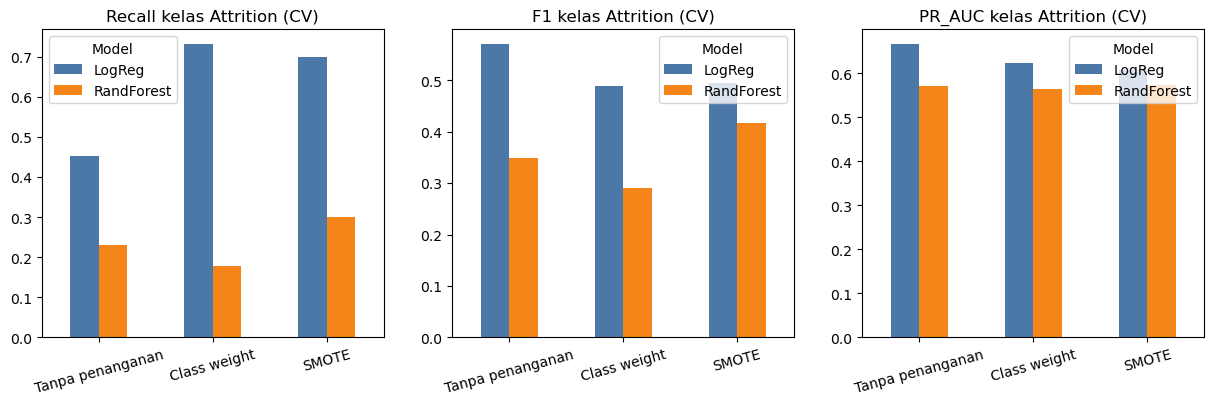

In [17]:
# Visualisasi before/after imbalance handling
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, metric in zip(axes, ["Recall", "F1", "PR_AUC"]):
    piv = cv_baseline.pivot(index="Imbalance", columns="Model", values=metric).loc[list(IMB_OPTIONS)]
    piv.plot(kind="bar", ax=ax, rot=15, color=["#4C78A8", "#F58518"])
    ax.set_title(f"{metric} kelas Attrition (CV)"); ax.set_xlabel("")

In [18]:
test_rows = []
for model_name in ["LogReg", "RandForest"]:
    for imb_name, imb in IMB_OPTIONS.items():
        pipe = build_pipeline(model_name, imb).fit(X_train, y_train)
        r = compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1])
        r.update(Model=model_name, Imbalance=imb_name)
        test_rows.append(r)

test_baseline = pd.DataFrame(test_rows)[["Model", "Imbalance", "Precision", "Recall", "F1", "BalAcc", "ROC_AUC", "PR_AUC"]]
display(test_baseline.round(3))

,Model,Imbalance,Precision,Recall,F1,BalAcc,ROC_AUC,PR_AUC
0,LogReg,Tanpa penanganan,0.593,0.340,0.432,0.648,0.818,0.581
1,LogReg,Class weight,0.367,0.617,0.460,0.707,0.809,0.558
2,LogReg,SMOTE,0.382,0.617,0.472,0.713,0.808,0.553
3,RandForest,Tanpa penanganan,0.545,0.128,0.207,0.554,0.777,0.443
4,RandForest,Class weight,0.625,0.106,0.182,0.547,0.793,0.454
5,RandForest,SMOTE,0.619,0.277,0.382,0.622,0.784,0.492


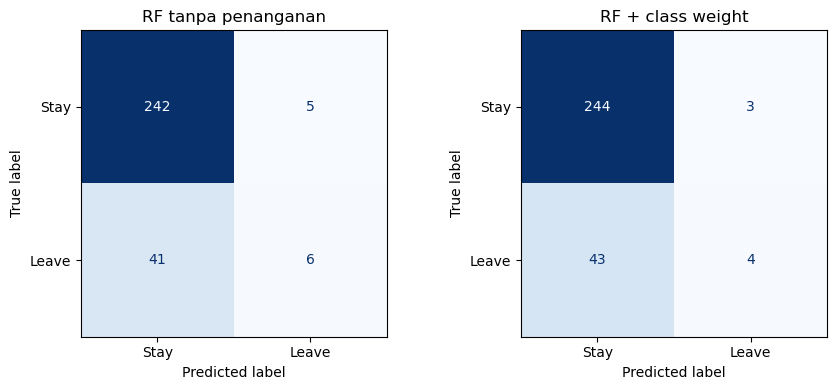

In [19]:
# Confusion matrix baseline (RF default tanpa penanganan vs RF + class weight)
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, imb) in zip(axes, [("RF tanpa penanganan", None), ("RF + class weight", "cw")]):
    pipe = build_pipeline("RandForest", imb).fit(X_train, y_train)
    ConfusionMatrixDisplay(confusion_matrix(y_test, pipe.predict(X_test)),
                           display_labels=["Stay", "Leave"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title)
plt.tight_layout(); plt.show()

#Fuzzy C Means (Segmentasi Profil)

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.metrics import silhouette_score

# Fitur untuk segmentasi (tanpa DailyRate/HourlyRate/MonthlyRate yang hampir acak)
CLUSTER_FEATS = ["Age", "MonthlyIncome", "TotalWorkingYears", "YearsAtCompany",
                 "YearsInCurrentRole", "YearsSinceLastPromotion", "YearsWithCurrManager",
                 "NumCompaniesWorked", "DistanceFromHome", "SatisfactionMean"]
M_FCM = 1.5   # m=2 membuat FCM runtuh di data ini

def _dist(data, V):
    return np.maximum(np.linalg.norm(data[:, None, :] - V[None, :, :], axis=2), 1e-10)

def _update_U(data, V, m):
    inv = _dist(data, V) ** (-2.0 / (m - 1))
    return inv / inv.sum(axis=1, keepdims=True)

def _kmeanspp_init(data, c, rng):
    V = [data[rng.integers(len(data))]]
    for _ in range(c - 1):
        d2 = np.min(np.linalg.norm(data[:, None, :] - np.array(V)[None], axis=2) ** 2, axis=1)
        V.append(data[rng.choice(len(data), p=d2 / d2.sum())])
    return np.array(V)

def fuzzy_c_means(data, c=3, m=2.0, max_iter=300, error=1e-6, seed=42, n_init=5):
    best = None
    for k in range(n_init):                      # multi-start, ambil objektif J terkecil
        rng = np.random.default_rng(seed + k)
        V = _kmeanspp_init(data, c, rng)
        U = _update_U(data, V, m)
        for _ in range(max_iter):
            U_old = U.copy()
            um = U ** m
            V = (um.T @ data) / um.sum(axis=0)[:, None]
            U = _update_U(data, V, m)
            if np.abs(U - U_old).max() < error:
                break
        J = np.sum((U ** m) * _dist(data, V) ** 2)
        if best is None or J < best[0]:
            best = (J, U, V)
    return best[1], best[2]

def fcm_predict(data, V, m=2.0):
    return _update_U(data, V, m)

def fpc(U):
    return np.sum(U ** 2) / U.shape[0]

def xie_beni(data, U, V, m=2.0):
    n, c = U.shape
    num = np.sum((U ** m) * _dist(data, V) ** 2)
    sep = min(np.sum((V[i] - V[j]) ** 2) for i in range(c) for j in range(i + 1, c))
    return num / (n * sep)

class FCMMembership(BaseEstimator, TransformerMixin):
    """FCM sebagai transformer: fit di data train fold, transform data validasi (tanpa leakage)."""
    def __init__(self, c=3, m=2.0, seed=42):
        self.c, self.m, self.seed = c, m, seed
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.scaler_ = StandardScaler().fit(X)
        _, self.V_ = fuzzy_c_means(self.scaler_.transform(X), self.c, self.m, seed=self.seed)
        return self
    def transform(self, X):
        return fcm_predict(self.scaler_.transform(np.asarray(X, dtype=float)), self.V_, self.m)

In [21]:
Xs = StandardScaler().fit_transform(df[CLUSTER_FEATS])
hasil = []
for c in [2, 3, 4, 5, 6]:
    U, V = fuzzy_c_means(Xs, c, m=M_FCM)
    lab = U.argmax(1)
    hasil.append({"c": c, "FPC": fpc(U), "Xie-Beni": xie_beni(Xs, U, V, M_FCM),
                  "Silhouette": silhouette_score(Xs, lab),
                  "Ukuran cluster": np.bincount(lab, minlength=c).tolist()})
display(pd.DataFrame(hasil).round(3))

,c,FPC,Xie-Beni,Silhouette,Ukuran cluster
0,2,0.758,0.649,0.268,"[947, 523]"
1,3,0.575,1.760,0.170,"[613, 372, 485]"
2,4,0.540,1.185,0.181,"[432, 181, 378, 479]"
3,5,0.480,1.493,0.172,"[353, 425, 154, 370, 168]"
4,6,0.453,1.238,0.172,"[231, 332, 136, 339, 136, 296]"


,Age,MonthlyIncome,TotalWorkingYears,YearsAtCompany,Attrition,n
FCM_Cluster,,,,,,
0,34.23,4516.82,7.60,3.89,0.2,947
1,41.80,10099.20,17.95,12.65,0.1,523


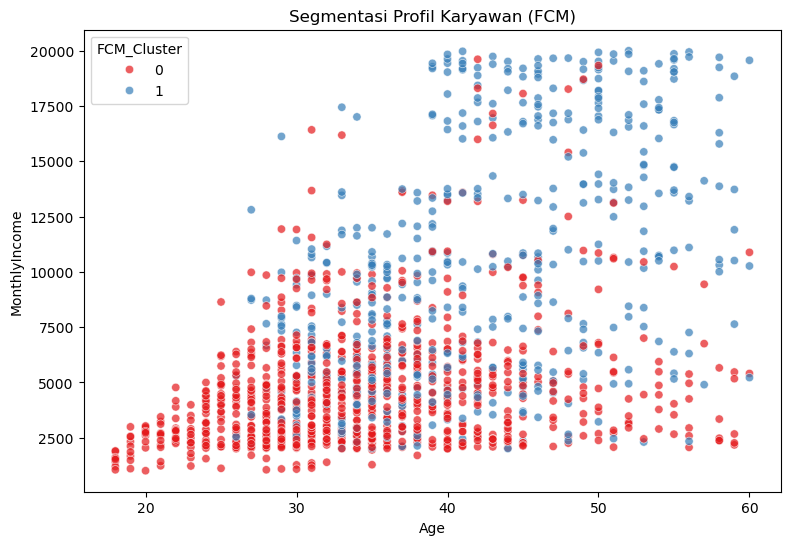

In [22]:
Xs = StandardScaler().fit_transform(df[CLUSTER_FEATS])
best_c = 2   # sesuaikan dengan keputusanmu dari tabel B2
U_final, V_final = fuzzy_c_means(Xs, best_c, m=M_FCM)
df["FCM_Cluster"] = U_final.argmax(1)

profil = df.groupby("FCM_Cluster")[["Age", "MonthlyIncome", "TotalWorkingYears",
                                    "YearsAtCompany", "Attrition"]].mean().round(2)
profil["n"] = df["FCM_Cluster"].value_counts().sort_index()
display(profil)

plt.figure(figsize=(9, 6))
sns.scatterplot(x=df["Age"], y=df["MonthlyIncome"], hue=df["FCM_Cluster"], palette="Set1", alpha=0.7)
plt.title("Segmentasi Profil Karyawan (FCM)"); plt.show()

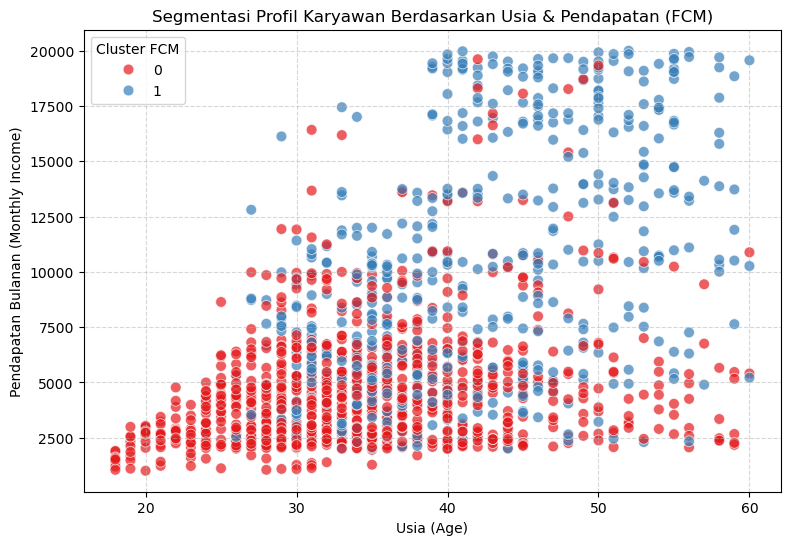

In [23]:
### 4. Visualisasi Sebaran Cluster FCM
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=df['Age'], 
    y=df['MonthlyIncome'], 
    hue=df['FCM_Cluster'], 
    palette='Set1', 
    alpha=0.7,
    s=60
)
plt.title("Segmentasi Profil Karyawan Berdasarkan Usia & Pendapatan (FCM)")
plt.xlabel("Usia (Age)")
plt.ylabel("Pendapatan Bulanan (Monthly Income)")
plt.legend(title="Cluster FCM")
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [24]:
def build_pipeline_fcm(model_name, imb=None, use_fcm=False, c=3):
    tr = [("num", StandardScaler(), CONT + ORD),
          ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)]
    if use_fcm:
        tr.append(("fcm", FCMMembership(c=c, m=M_FCM, seed=SEED), CLUSTER_FEATS))
    steps = [("pre", ColumnTransformer(tr))]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", make_model(model_name)))
    return ImbPipeline(steps)

rows = []
for model in ["LogReg", "RandForest"]:
    for imb_name, imb in {"Tanpa penanganan": None, "SMOTE": "smote"}.items():
        for use in [False, True]:
            r = run_cv(build_pipeline_fcm(model, imb, use, best_c), X_train, y_train)
            r.update(Model=model, Imbalance=imb_name, FCM="Dengan" if use else "Tanpa")
            rows.append(r)

abl = pd.DataFrame(rows)
tampil = abl[["Model", "Imbalance", "FCM"]].copy()
for m in ["Recall", "F1", "PR_AUC", "ROC_AUC"]:
    tampil[m] = abl.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
display(tampil)

,Model,Imbalance,FCM,Recall,F1,PR_AUC,ROC_AUC
0,LogReg,Tanpa penanganan,Tanpa,0.453 ± 0.082,0.570 ± 0.080,0.667 ± 0.059,0.841 ± 0.030
1,LogReg,Tanpa penanganan,Dengan,0.479 ± 0.077,0.590 ± 0.077,0.671 ± 0.057,0.843 ± 0.029
2,LogReg,SMOTE,Tanpa,0.700 ± 0.079,0.495 ± 0.029,0.608 ± 0.068,0.826 ± 0.032
3,LogReg,SMOTE,Dengan,0.711 ± 0.073,0.514 ± 0.033,0.622 ± 0.064,0.832 ± 0.031
4,RandForest,Tanpa penanganan,Tanpa,0.232 ± 0.096,0.349 ± 0.116,0.571 ± 0.046,0.816 ± 0.029
5,RandForest,Tanpa penanganan,Dengan,0.200 ± 0.089,0.311 ± 0.119,0.532 ± 0.079,0.799 ± 0.043
6,RandForest,SMOTE,Tanpa,0.300 ± 0.064,0.417 ± 0.067,0.573 ± 0.047,0.814 ± 0.037
7,RandForest,SMOTE,Dengan,0.316 ± 0.073,0.444 ± 0.074,0.588 ± 0.036,0.817 ± 0.032


### Ensemble Learning + Genetic Algoritm

In [25]:
import time
import random

import xgboost as xgb
from xgboost import XGBClassifier

# Pastikan bagian anggota 1 sudah dijalankan (variabel dan fungsi bersama)
dibutuhkan = ["X_train", "X_test", "y_train", "y_test",
              "CONT", "ORD", "CAT", "SEED", "SCORING", "run_cv", "get_cv"]
hilang = [n for n in dibutuhkan if n not in globals()]
assert not hilang, f"Jalankan dulu cell anggota 1, belum ada: {hilang}"

print("XGBoost :", xgb.__version__)
print("Pandas  :", pd.__version__)
print("Train   :", X_train.shape, "| Test:", X_test.shape)
print("Attrition di train:", round(y_train.mean(), 4))

ModuleNotFoundError: No module named 'xgboost'

### Baseline XGBoost

In [ ]:
def build_ens_pipeline(model, imb=None):
    """Preprocessing -> (SMOTE opsional) -> model. Semua langkah di dalam fold CV."""
    pre = ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    steps = [("pre", pre)]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", model))
    return ImbPipeline(steps)

def xgb_default(**kw):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **kw)

# Rasio kelas negatif : positif pada data latih, untuk scale_pos_weight
spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(spw, 3))

scale_pos_weight = 5.189


##### Hasil Cross-Validation Baseline

In [ ]:
skenario = {
    "XGB default | tanpa penanganan": (xgb_default(), None),
    "XGB default | scale_pos_weight": (xgb_default(scale_pos_weight=spw), None),
    "XGB default | SMOTE":            (xgb_default(), "smote"),
}

rows = []
for nama, (model, imb) in skenario.items():
    t = time.time()
    r = run_cv(build_ens_pipeline(model, imb), X_train, y_train)
    r["Skenario"] = nama
    r["Waktu (dtk)"] = round(time.time() - t, 1)
    rows.append(r)

hasil_xgb = pd.DataFrame(rows)
tampil = hasil_xgb[["Skenario"]].copy()
for m in ["Recall", "F1", "PR_AUC", "ROC_AUC"]:
    tampil[m] = hasil_xgb.apply(lambda r: f"{r[m]:.3f} ± {r[m+'_std']:.3f}", axis=1)
tampil["Waktu (dtk)"] = hasil_xgb["Waktu (dtk)"]
display(tampil)

,Skenario,Recall,F1,PR_AUC,ROC_AUC,Waktu (dtk)
0,XGB default | tanpa penanganan,0.332 ± 0.046,0.450 ± 0.036,0.569 ± 0.035,0.804 ± 0.028,1.4
1,XGB default | scale_pos_weight,0.400 ± 0.071,0.491 ± 0.075,0.564 ± 0.059,0.797 ± 0.024,0.8
2,XGB default | SMOTE,0.374 ± 0.077,0.471 ± 0.074,0.570 ± 0.056,0.804 ± 0.031,1.3


### Ruang Pencarian Hyperparameter dan Fungsi Fitness

In [ ]:
# (tipe, batas bawah, batas atas); "log" = dicari pada skala logaritmik
SEARCH_SPACE = {
    "n_estimators":     ("int",   50,    500),
    "max_depth":        ("int",   2,     10),
    "learning_rate":    ("log",   0.01,  0.3),
    "subsample":        ("float", 0.5,   1.0),
    "colsample_bytree": ("float", 0.5,   1.0),
    "min_child_weight": ("int",   1,     10),
    "gamma":            ("float", 0.0,   5.0),
    "reg_lambda":       ("log",   0.1,   10.0),
    "reg_alpha":        ("log",   0.001, 10.0),
    "scale_pos_weight": ("float", 1.0,   10.0),   # rasio kelas di data latih = 5,19
}
PARAM_NAMES = list(SEARCH_SPACE)
N_GENES = len(PARAM_NAMES)

FITNESS_METRIC = "PR_AUC"   # bisa diganti "F1" atau "Recall"

def decode(vec):
    """Vektor gen [0,1]^N -> dict hyperparameter XGBoost."""
    params = {}
    for g, name in zip(vec, PARAM_NAMES):
        kind, lo, hi = SEARCH_SPACE[name]
        g = float(np.clip(g, 0.0, 1.0))
        if kind == "log":
            v = float(np.exp(np.log(lo) + g * (np.log(hi) - np.log(lo))))
        else:
            v = lo + g * (hi - lo)
        params[name] = int(round(v)) if kind == "int" else float(v)
    return params

print("Jumlah gen:", N_GENES)
print("Titik tengah ruang pencarian:")
display(pd.Series(decode(np.full(N_GENES, 0.5))))

Jumlah gen: 10
Titik tengah ruang pencarian:


n_estimators        275.000000
max_depth             6.000000
learning_rate         0.054772
subsample             0.750000
colsample_bytree      0.750000
min_child_weight      6.000000
gamma                 2.500000
reg_lambda            1.000000
reg_alpha             0.100000
scale_pos_weight      5.500000
dtype: float64

##### Fungsi Evaluasi (Fitness)

In [ ]:
def make_xgb(params):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **params)

class Evaluator:
    """Menghitung fitness, mencatat riwayat, dan menghitung jumlah evaluasi model yang sebenarnya."""
    def __init__(self, metric=FITNESS_METRIC):
        self.metric, self.cache, self.history = metric, {}, []

    def __call__(self, vec):
        params = decode(vec)
        key = tuple((k, round(v, 6)) for k, v in sorted(params.items()))
        if key in self.cache:                       # kandidat sama: tidak dihitung ulang
            return self.cache[key]
        r = run_cv(build_ens_pipeline(make_xgb(params)), X_train, y_train)
        score = r[self.metric]
        self.cache[key] = score
        self.history.append({"eval": len(self.history) + 1, "score": score,
                             "F1": r["F1"], "Recall": r["Recall"], **params})
        return score

    @property
    def n_evals(self):
        return len(self.history)

##### Uji Coba Fungsi Fitness

In [ ]:
uji = Evaluator()
rng = np.random.default_rng(SEED)

t = time.time()
s_tengah = uji(np.full(N_GENES, 0.5))
print(f"Skor titik tengah ({FITNESS_METRIC}): {s_tengah:.4f} | waktu: {time.time()-t:.1f} dtk")
print("Evaluasi ulang memakai cache:", uji(np.full(N_GENES, 0.5)) == s_tengah, "| n_evals =", uji.n_evals)

for _ in range(5):
    uji(rng.random(N_GENES))
display(pd.DataFrame(uji.history)[["eval", "score", "F1", "Recall", "n_estimators",
                                   "max_depth", "learning_rate", "scale_pos_weight"]].round(3))

Skor titik tengah (PR_AUC): 0.6264 | waktu: 2.0 dtk
Evaluasi ulang memakai cache: True | n_evals = 1


,eval,score,F1,Recall,n_estimators,max_depth,learning_rate,scale_pos_weight
0,1,0.626,0.544,0.532,275,6,0.055,5.500
1,2,0.600,0.524,0.563,398,6,0.185,5.053
2,3,0.592,0.541,0.568,217,9,0.089,6.685
3,4,0.549,0.523,0.532,391,5,0.272,7.147
4,5,0.613,0.529,0.468,385,10,0.030,7.028
5,6,0.606,0.546,0.484,247,9,0.108,2.258


### Random Search

In [ ]:
import os

BUDGET = 200            # jumlah evaluasi model per run (sama untuk Random Search dan GA)
SEEDS = [42, 43, 44]    # pengulangan untuk menguji kestabilan
os.makedirs("hasil_search", exist_ok=True)

def random_search(budget, seed):
    rng = np.random.default_rng(seed)
    ev = Evaluator()
    t = time.time()
    while ev.n_evals < budget:
        ev(rng.random(N_GENES))
    ev.waktu = time.time() - t
    return ev

In [ ]:
rs_runs = {}
for seed in SEEDS:
    ev = random_search(BUDGET, seed)
    rs_runs[seed] = ev
    pd.DataFrame(ev.history).to_csv(f"hasil_search/rs_seed{seed}.csv", index=False)
    print(f"Seed {seed}: {ev.n_evals} evaluasi | best {FITNESS_METRIC} = "
          f"{max(h['score'] for h in ev.history):.4f} | {ev.waktu/60:.1f} menit", flush=True)

Seed 42: 200 evaluasi | best PR_AUC = 0.6386 | 2.5 menit
Seed 43: 200 evaluasi | best PR_AUC = 0.6514 | 2.6 menit
Seed 44: 200 evaluasi | best PR_AUC = 0.6334 | 2.6 menit


##### Ringkasan & Konvergensi

,Seed,Best PR_AUC (CV),F1,Recall,scale_pos_weight,max_depth,learning_rate,n_estimators
0,42,0.639,0.537,0.437,1.835,7.0,0.164,66.0
1,43,0.651,0.515,0.379,1.127,10.0,0.067,482.0
2,44,0.633,0.523,0.405,1.101,3.0,0.133,450.0


Rata-rata best: 0.6411 ± 0.0092


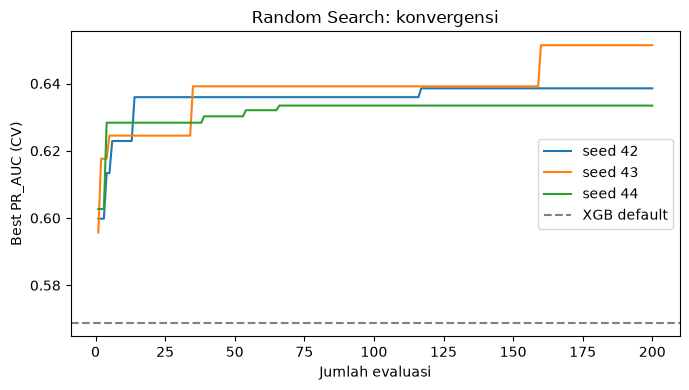

Kandidat yang mengalahkan default: 94.3%


In [ ]:
ringkas = []
for seed, ev in rs_runs.items():
    h = pd.DataFrame(ev.history)
    b = h.loc[h["score"].idxmax()]
    ringkas.append({"Seed": seed, "Best PR_AUC (CV)": b["score"], "F1": b["F1"],
                    "Recall": b["Recall"], "scale_pos_weight": b["scale_pos_weight"],
                    "max_depth": b["max_depth"], "learning_rate": b["learning_rate"],
                    "n_estimators": b["n_estimators"]})
ringkas = pd.DataFrame(ringkas)
display(ringkas.round(3))
print(f"Rata-rata best: {ringkas['Best PR_AUC (CV)'].mean():.4f} ± {ringkas['Best PR_AUC (CV)'].std():.4f}")

fig, ax = plt.subplots(figsize=(7, 4))
for seed, ev in rs_runs.items():
    s = pd.Series([h["score"] for h in ev.history]).cummax()
    ax.plot(range(1, len(s) + 1), s, label=f"seed {seed}")
ax.axhline(hasil_xgb.loc[0, "PR_AUC"], color="gray", ls="--", label="XGB default")
ax.set_xlabel("Jumlah evaluasi"); ax.set_ylabel(f"Best {FITNESS_METRIC} (CV)")
ax.set_title("Random Search: konvergensi"); ax.legend(); plt.tight_layout(); plt.show()

semua = pd.concat([pd.DataFrame(e.history) for e in rs_runs.values()])
print(f"Kandidat yang mengalahkan default: {(semua['score'] > hasil_xgb.loc[0, 'PR_AUC']).mean():.1%}")

In [26]:
   pip install optuna shap

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 544.4/544.4 kB 4.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [optuna]2m5/6 [optuna]
Note: you may need to restart the kernel to use updated packages.


In [27]:
   [k for k in globals() if "run" in k.lower() or k in ("X_train","y_train","X_test","y_test")]

['X_train', 'X_test', 'y_train', 'y_test', 'run_cv']

# Optimasi Multi-Objective NSGA-II & Evaluasi Akhir
Objektif (maksimalkan keduanya): PR-AUC dan Recall kelas Attrition, dihitung dengan `run_cv`
yang sama dengan Random Search dan GA (budget 200 evaluasi, seed 42/43/44, population 20).

In [29]:
%pip install xgboost
import time
import xgboost as xgb
from xgboost import XGBClassifier

SEEDS = [42, 43, 44]
BUDGET = 200

SEARCH_SPACE = {
    "n_estimators":     ("int",   50,    500),
    "max_depth":        ("int",   2,     10),
    "learning_rate":    ("log",   0.01,  0.3),
    "subsample":        ("float", 0.5,   1.0),
    "colsample_bytree": ("float", 0.5,   1.0),
    "min_child_weight": ("int",   1,     10),
    "gamma":            ("float", 0.0,   5.0),
    "reg_lambda":       ("log",   0.1,   10.0),
    "reg_alpha":        ("log",   0.001, 10.0),
    "scale_pos_weight": ("float", 1.0,   10.0),
}

def build_ens_pipeline(model, imb=None):
    pre = ColumnTransformer([
        ("num", StandardScaler(), CONT + ORD),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])
    steps = [("pre", pre)]
    if imb == "smote":
        steps.append(("smote", SMOTE(random_state=SEED)))
    steps.append(("clf", model))
    return ImbPipeline(steps)

def make_xgb(params):
    return XGBClassifier(random_state=SEED, n_jobs=-1, eval_metric="logloss", **params)

spw = (y_train == 0).sum() / (y_train == 1).sum()
print("scale_pos_weight =", round(spw, 3))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 3.1 MB/s  0:00:00 eta 0:00:01
Note: you may need to restart the kernel to use updated packages.
scale_pos_weight = 5.189


In [30]:
import optuna, shap, os, time
optuna.logging.set_verbosity(optuna.logging.WARNING)
os.makedirs("hasil_search", exist_ok=True)

dibutuhkan = ["X_train", "X_test", "y_train", "y_test", "run_cv", "build_ens_pipeline",
              "make_xgb", "compute_metrics", "SEARCH_SPACE", "SEEDS", "BUDGET", "spw"]
hilang = [n for n in dibutuhkan if n not in globals()]
assert not hilang, f"Jalankan dulu cell di atas, belum ada: {hilang}"
print("Optuna:", optuna.__version__, "| SHAP:", shap.__version__)

Optuna: 5.0.0 | SHAP: 0.54.1


In [31]:
#Fungsi Objektif
def params_from_trial(trial):
    """Search space identik dengan SEARCH_SPACE milik Random Search dan GA."""
    p = {}
    for name, (kind, lo, hi) in SEARCH_SPACE.items():
        if kind == "int":
            p[name] = trial.suggest_int(name, lo, hi)
        elif kind == "log":
            p[name] = trial.suggest_float(name, lo, hi, log=True)
        else:
            p[name] = trial.suggest_float(name, lo, hi)
    return p

def objective(trial):
    params = params_from_trial(trial)
    r = run_cv(build_ens_pipeline(make_xgb(params)), X_train, y_train)
    trial.set_user_attr("F1", r["F1"])
    trial.set_user_attr("Precision", r["Precision"])
    return r["PR_AUC"], r["Recall"]          # dua objektif, keduanya dimaksimalkan